# 📐 Measure Fidelity: Distributional Similarity and Visual Checks

In this lesson we will explore how to quantify how close synthetic data is to the original, by implementing a similarity metrics and interpreting them.

**In this notebook, we will:**
1. Load the original and synthetic Bank Marketing datasets
2. Implement Jensen-Shannon divergence to measure distributional similarity
3. Generate a `SyntheticDataProfile` report and walk through its sections

## Load the datasets

We load the original Bank Marketing dataset and the synthetic version generated in Chapter 2.

> **Note on holdout:** the synthesizer automatically held out a portion of the original data during training — that split is never used to fit the model. Here we compare against the full original dataset, so this evaluation is indicative rather than strict. In a production pipeline you would evaluate against the holdout split only.

In [1]:
import pandas as pd
import numpy as np
# Replace these paths with your own CSV files
original_df  = pd.read_csv('../data/bank-full.csv', sep=';')
synthetic_df = pd.read_csv('../data/bank-full_synthetic.csv')

print(f'Original : {original_df.shape[0]:,} rows × {original_df.shape[1]} columns')
print(f'Synthetic: {synthetic_df.shape[0]:,} rows × {synthetic_df.shape[1]} columns')

Original : 45,211 rows × 17 columns
Synthetic: 45,211 rows × 17 columns


In [2]:
original_df = original_df.drop('duration', axis=1) # removing the calculated feature created
synthetic_df = synthetic_df.drop('total_contacts', axis=1) # removing the calculated feature created

In [ ]:
from ydata.profiling import ProfileReport

report = ProfileReport(original_df, title='Original bank dataset')
report_synth = ProfileReport(synthetic_df, title='Synthetic bank dataset')

compare = report.compare(report_synth)
compare

## 2. Jensen-Shannon Divergence

Before reaching for an automated report, it is worth understanding what we are actually measuring. as an exercise here's an example of one of the most commonly used metrics to mathematically assess how similar two probability distributions are - **Jensen-Shannon (JS) divergence**.

For synthetic data evaluation, this is one of the metrics that it answers: *does the synthetic column have the same shape as the original?*

- **JS = 0.0** — identical distributions
- **JS = 1.0** — completely different distributions
- **JS < 0.1** is generally considered high fidelity

Unlike KL divergence, JS divergence is symmetric (order of comparison does not matter) and bounded, which makes it practical to interpret and compare across columns.

In [3]:
from scipy.spatial.distance import jensenshannon

def js_divergence(original: pd.Series, synthetic: pd.Series) -> float:
    """Compute Jensen-Shannon divergence between two columns."""
    if original.dtype == 'object' or str(original.dtype) == 'category':
        # Categorical: compare frequency distributions
        categories = set(original.unique()) | set(synthetic.unique())
        p = original.value_counts(normalize=True).reindex(categories, fill_value=0)
        q = synthetic.value_counts(normalize=True).reindex(categories, fill_value=0)
    else:
        # Numerical: bin into a histogram with shared bin edges
        combined = pd.concat([original, synthetic])
        bins = np.histogram_bin_edges(combined.dropna(), bins=50)
        p, _ = np.histogram(original.dropna(), bins=bins, density=True)
        q, _ = np.histogram(synthetic.dropna(), bins=bins, density=True)
        p, q = p + 1e-10, q + 1e-10   # avoid zeros before normalising
        p, q = p / p.sum(), q / q.sum()

    return round(float(jensenshannon(p, q)), 4)

In [4]:
# Compute JS divergence for every shared column
shared_cols = [c for c in original_df.columns if c in synthetic_df.columns]

scores = [
    {
        'column': col,
        'dtype':  str(original_df[col].dtype),
        'js_divergence': js_divergence(original_df[col], synthetic_df[col]),
    }
    for col in shared_cols
]

scores_df = pd.DataFrame(scores).sort_values('js_divergence', ascending=False)
scores_df

,column,dtype,js_divergence
0,age,int64,0.0152
12,pdays,int64,0.0143
11,campaign,int64,0.0140
9,day,int64,0.0109
5,balance,int64,0.0099
13,previous,int64,0.0096
1,job,object,0.0073
14,poutcome,object,0.0071
15,y,object,0.0063
10,month,object,0.0053


In [5]:
# Summary
print(f'Mean JS divergence : {scores_df["js_divergence"].mean():.4f}')
print(f'Columns JS < 0.1   : {(scores_df["js_divergence"] < 0.1).sum()} / {len(scores_df)}')
print(f'\nHighest divergence:')
print(scores_df.head(3).to_string(index=False))

Mean JS divergence : 0.0066
Columns JS < 0.1   : 16 / 16

Highest divergence:
  column dtype  js_divergence
     age int64         0.0152
   pdays int64         0.0143
campaign int64         0.0140


## 3. Synthetic Data Quality Report

JS divergence gives us one metric per column. The `SyntheticDataProfile` report scales this to every dimension of fidelity simultaneously:  distribution similarity, relationship preservation, coverage, and a dimensionality reduction view — and exports everything as a PDF.

This is what production evaluation looks like: the same rigour as the manual metric above, applied automatically across the full dataset.

INFO: 2026-08-25 10:39:44,115 Using device of type: cpu


Done:  80%|████████████████████████████▊       | 4/5 [00:00<00:00,  5.36step/s]

INFO: 2026-08-25 10:39:45,844 [PROFILEREPORT] - Starting metrics calculation.
INFO: 2026-08-25 10:39:45,950 [PROFILEREPORT] - Synthetic data quality report selected target variable: None
INFO: 2026-08-25 10:39:45,959 [PROFILEREPORT] - preparing data format.
INFO: 2026-08-25 10:39:46,022 [PROFILEREPORT] - Preparing the data for metrics calculation


INFO: 2026-08-25 10:39:46,174 [PROFILEREPORT] - Calculating privacy metrics.
INFO: 2026-08-25 10:39:46,182 [PROFILEREPORT] - Calculating metric [Exact Matches].
INFO: 2026-08-25 10:39:46,375 [PROFILEREPORT] - Metric [Exact Matches] took 0.19s.
INFO: 2026-08-25 10:39:46,381 [PROFILEREPORT] - Calculating metric [Identifiability Risk].
INFO: 2026-08-25 10:39:47,311 [PROFILEREPORT] - Metric [Identifiability Risk] took 0.93s.
INFO: 2026-08-25 10:39:47,312 [PROFILEREPORT] - Calculating fidelity metrics.
INFO: 2026-08-25 10:39:47,323 [PROFILEREPORT] - Calculating metric [Correlation Similarity].
INFO: 2026-08-25 10:39:48,381 [PROFILEREPORT] - Metric [Correlation Similarity] took 1.06s.
INFO: 2026-08-25 10:39:48,383 [PROFILEREPORT] - Calculating metric [Distance Distribution].
INFO: 2026-08-25 10:39:48,483 [PROFILEREPORT] - Metric [Distance Distribution] took 0.10s.
INFO: 2026-08-25 10:39:48,487 [PROFILEREPORT] - Calculating metric [Statistical Similarity].
INFO: 2026-08-25 10:39:48,506 [PROFI

# Real data records: 45K
# Synthetic data records generated: 45K
# Columns: 16
Fidelity Score: Excellent
Utility Score: Excellent
Privacy Score: Moderate


Correlation Similarity: 1.00
Distance Distribution: 1.00
Synthetic Classifier: 1.00
Mutual Information: 0.99
Missing Values Similarity: 1.00
Mean Similarity: 1.00
Std. Dev. Similarity: 1.00
Median Similarity: 1.00
Q25% Similarity: 1.00
Q75% Similarity: 1.00
Kolmogorov-Smirnov Test: 1.00
Total Variation Distance: 1.00
Category Coverage: 1.00
Missing Category Coverage: 0.99
Range Coverage: 0.84


QScore: 0.97


Exact Matches: 0.06
Identifiability Risk: 0.59


FileNotFoundError: [Errno 2] No such file or directory: 'output/bank_marketing_fidelity_report.pdf'

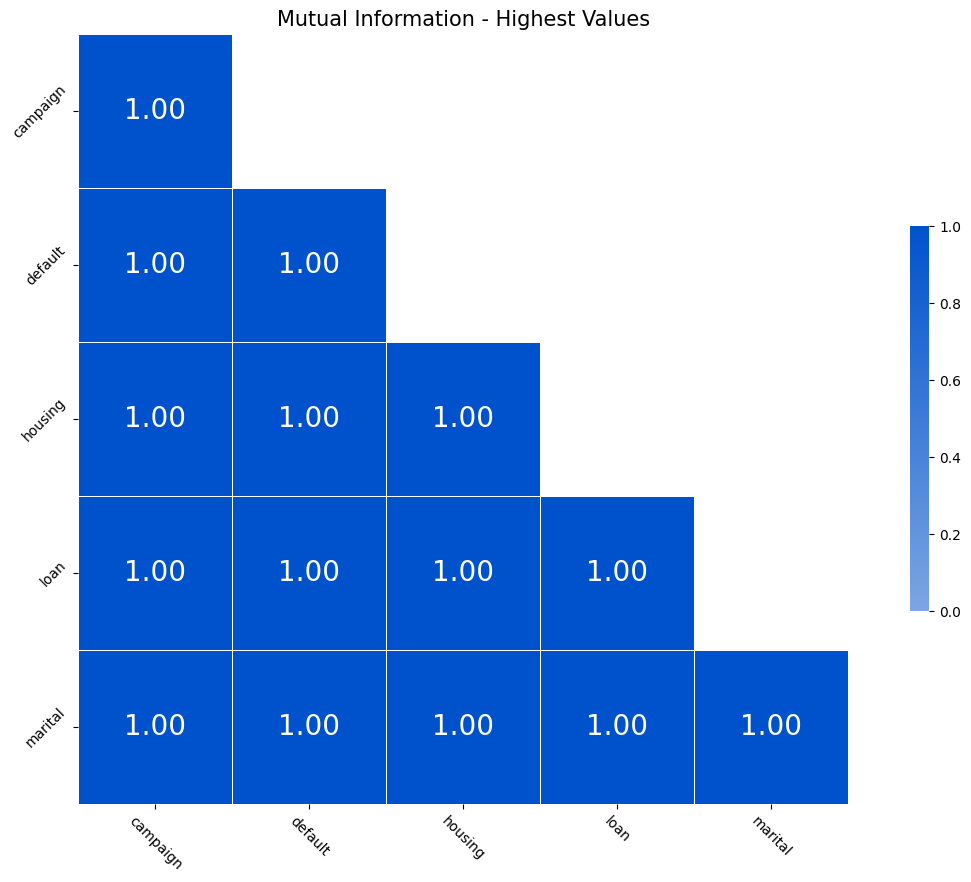

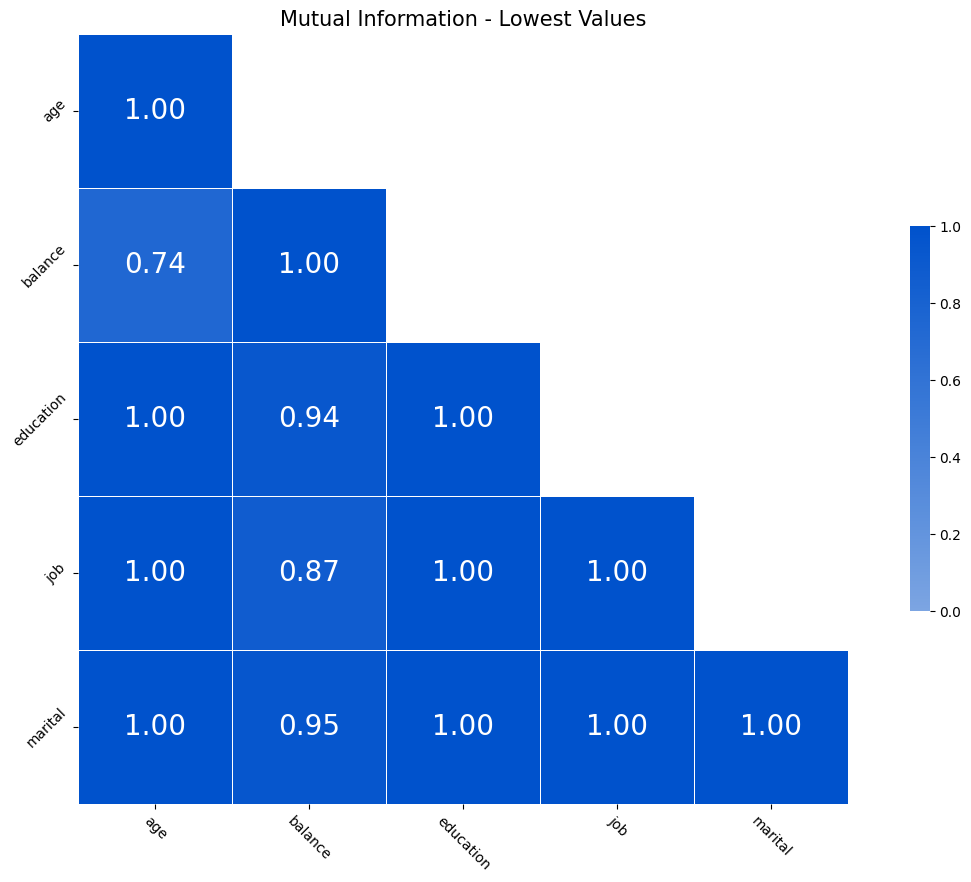

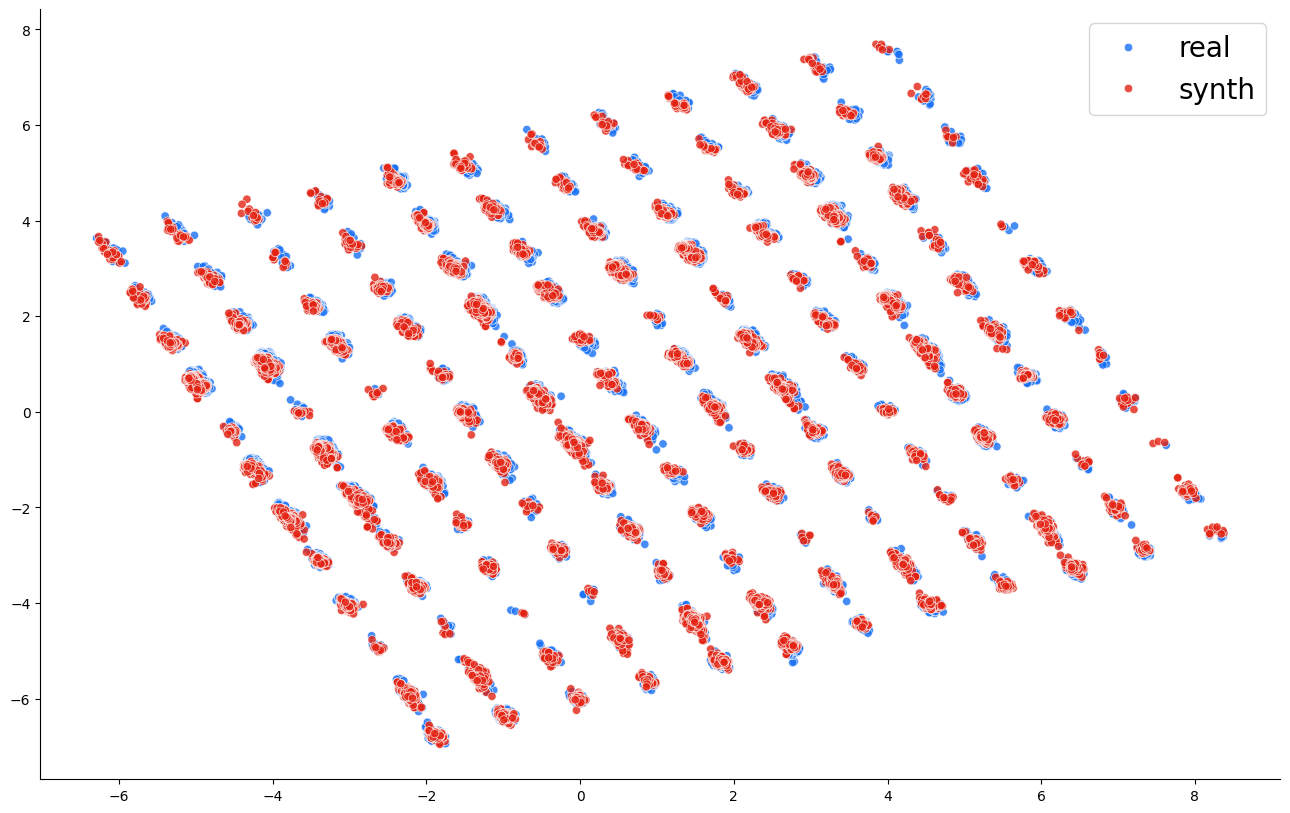

In [6]:
from ydata.dataset import Dataset
from ydata.metadata import Metadata
from ydata.report import SyntheticDataProfile

original_dataset  = Dataset(original_df)
synthetic_dataset = Dataset(synthetic_df)
metadata          = Metadata(original_dataset)

profile = SyntheticDataProfile(
    original_dataset,
    synthetic_dataset,
    metadata=metadata,
)

profile.generate_report(output_path='output/bank_marketing_fidelity_report.pdf')
print('Report generated → output/bank_marketing_fidelity_report.pdf ✓')

## ✅ Summary

In this notebook you:

1. **Implemented Jensen-Shannon divergence** from scratch — understanding what distributional similarity actually measures before relying on automated tools
2. **Generated a `SyntheticDataProfile` report** — production-grade fidelity evaluation covering distribution similarity, relationship preservation, coverage, and dimensionality reduction in a single PDF
3. **Learned to read the report** — knowing what each section measures and what a gap in that section means for a downstream AI system